# D2 — Local explainability: TreeSHAP and LIME per finding

SHAP (log-odds) and LIME (`LimeTabularExplainer`: continuous features, `sample_around_instance=True`, 5,000 samples, all 69 features, explaining P(KEV)) for both models, on E-rand (1,000 random complete-case test CVEs) ∪ E-top (top-10 per month, 460) ∪ E-kev (308 KEV positives). The nine case studies follow a fixed rule: from E-top under M-XGB, the three highest-ranked KEV hits and the three highest-ranked non-KEV CVEs; from E-kev, the three KEV CVEs ranked lowest in their month. Design: Study D addendum (commit c0a3ee1), registered before any Study D explanation was computed.

Reads saved outputs. Run: `python -m src.explainability.shap_local` (~3 min). Attributions are cached for D5.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

## How well does LIME's local surrogate fit? (local R²)

In [2]:
pd.read_csv("outputs/d2_lime_r2.csv").round(3)

,model,set,n,lime_r2_median,lime_r2_q25,lime_r2_q75
0,xgboost,E-rand,1000,0.374,0.363,0.385
1,xgboost,E-top,460,0.429,0.409,0.476
2,xgboost,E-kev,308,0.382,0.368,0.399
3,logreg,E-rand,1000,0.395,0.339,0.463
4,logreg,E-top,460,0.693,0.659,0.738
5,logreg,E-kev,308,0.530,0.450,0.603


LIME's linear surrogate explains only **about 37% of the variance** of M-XGB around a typical CVE (median R² 0.37), and 0.43 in the top-10. It fits M-LR better: 0.69 in the top-10, where the logistic curve is steepest.

## Case studies

In [3]:
pd.read_csv("outputs/d2_case_studies.csv")

,case,cve_id,month,score,rank_in_month,kev,shap_top3,lime_top3,top3_overlap
0,top-ranked KEV hit,CVE-2024-9465,2024-11,0.314647,1,1,epss_pit +2.84; cvss_version +2.70; epss_pit_p...,cvss_version +0.1292; epss_pit_pct +0.0432; te...,2
1,top-ranked KEV hit,CVE-2024-9463,2024-11,0.294229,2,1,epss_pit +3.01; cvss_version +2.67; epss_pit_p...,cvss_version +0.1323; epss_pit_pct +0.0431; te...,2
2,top-ranked KEV hit,CVE-2025-3248,2025-05,0.293842,1,1,epss_pit +2.68; cvss_version +2.64; epss_pit_p...,cvss_version +0.1348; epss_pit_pct +0.0432; te...,2
3,"top-ranked, not in KEV",CVE-2025-29927,2025-04,0.476433,1,0,epss_pit +3.08; cvss_version +2.66; epss_pit_p...,cvss_version +0.1481; epss_pit_pct +0.0493; ep...,3
4,"top-ranked, not in KEV",CVE-2024-32640,2025-09,0.429404,1,0,epss_pit +3.09; cvss_version +2.58; epss_pit_p...,cvss_version +0.1321; epss_pit_pct +0.0452; te...,2
5,"top-ranked, not in KEV",CVE-2024-29973,2024-07,0.420656,1,0,epss_pit +3.01; cvss_version +2.71; epss_pit_p...,cvss_version +0.1526; epss_pit_pct +0.0496; te...,2
6,"KEV, ranked lowest in its month",CVE-2026-111793,2026-11,0.001312,14769,1,cvss_version +1.85; epss_pit -0.40; cvss_score...,epss_pit +0.0032; cvss_version +0.0031; text_2...,2
7,"KEV, ranked lowest in its month",CVE-2026-96656,2026-10,0.001179,8779,1,cvss_version +1.87; epss_pit -0.42; text_10 [p...,epss_pit +0.0047; cvss_version +0.0047; text_0...,2
8,"KEV, ranked lowest in its month",CVE-2026-96654,2026-10,0.001180,8770,1,cvss_version +1.84; epss_pit -0.40; epss_pit_p...,cvss_version +0.0042; epss_pit +0.0039; text_2...,2


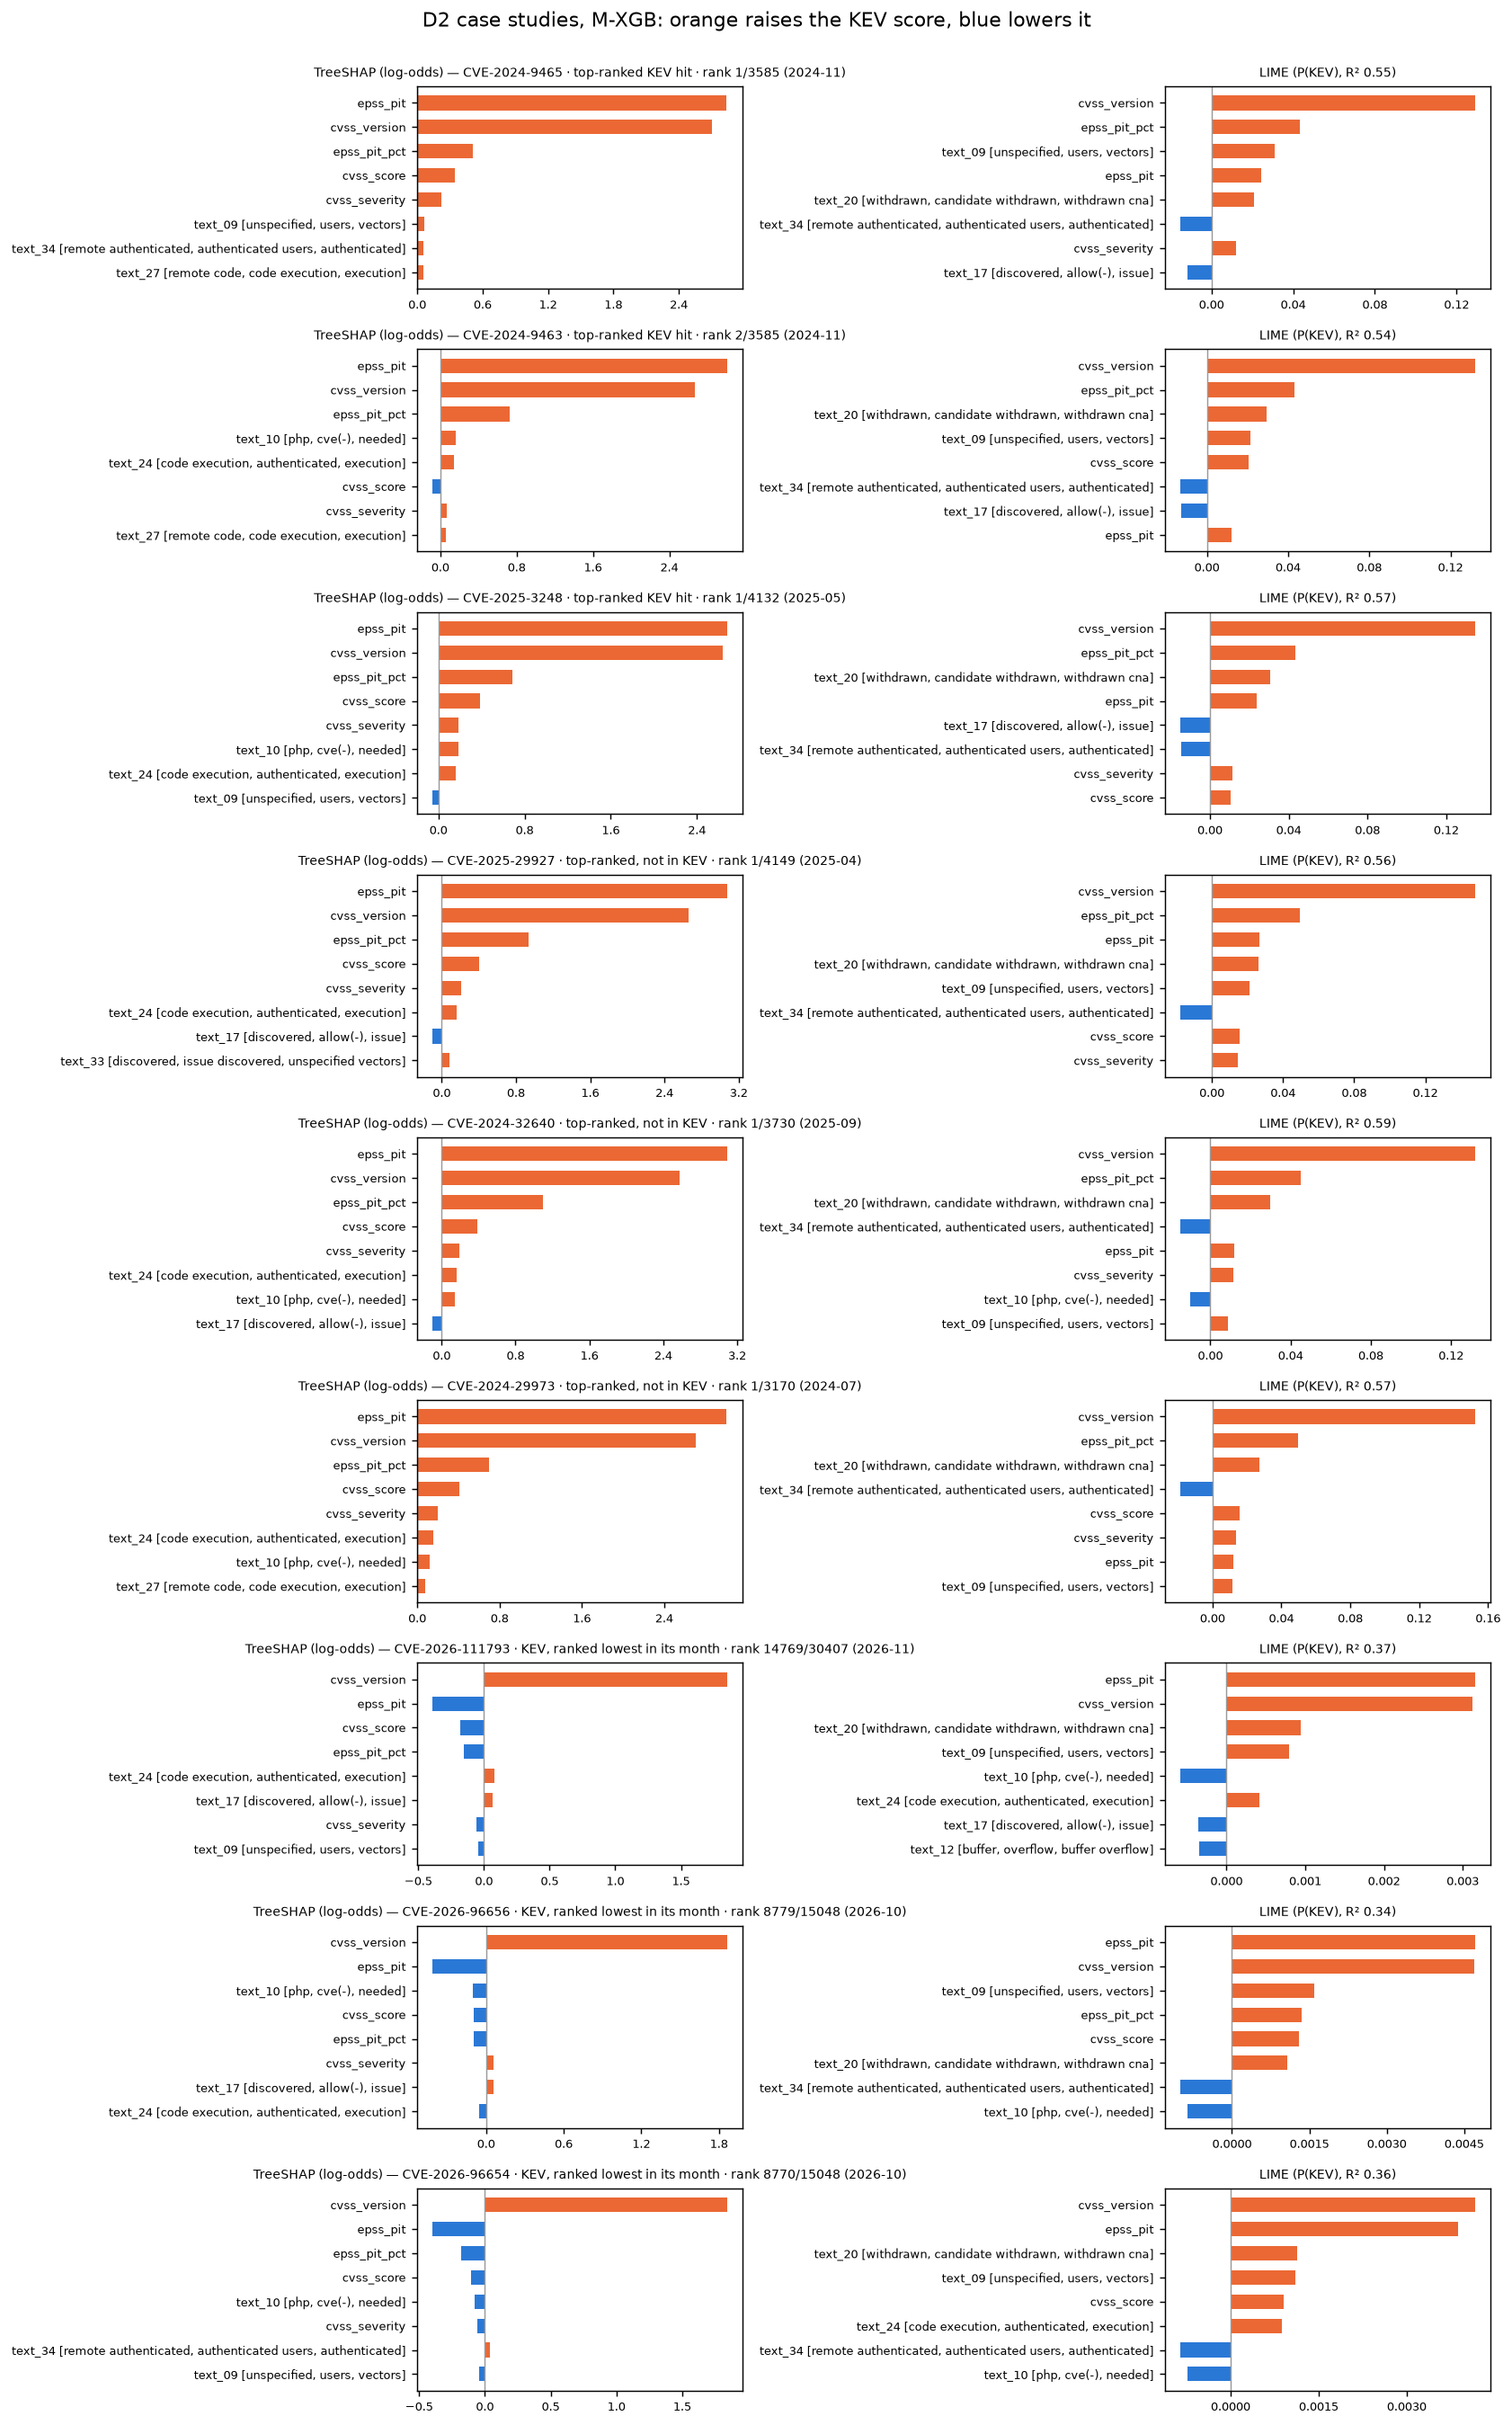

In [4]:
Image("outputs/d2_case_studies.png")

**Reading.**
- **Top-ranked CVEs** (KEV hits and non-hits look alike): SHAP says high EPSS-PIT (+2.7 to +3.1 log-odds), then `cvss_version` (+2.6 to +2.7), then the EPSS percentile. The model cannot tell the three KEV hits from the three non-hits, and neither can the explanation. One "top-ranked, not in KEV" CVE (CVE-2025-29927) is widely reported as exploited, which is a reminder that KEV is a partial label.
- **KEV CVEs the model ranks low:** SHAP says low EPSS at scoring time (−0.4) is the reason, and `cvss_version` (+1.85) is again the biggest attribution. At scoring time these CVEs looked like everything else; the information was not there yet.
- **SHAP and LIME read differently at the top of the list.** LIME ranks `cvss_version` first in most cases, and it can flip a sign: for the low-ranked KEV CVEs, SHAP gives EPSS −0.40 (below the background), while LIME gives EPSS a positive weight (raising EPSS locally would raise the score). The two methods answer different questions, deviation from a baseline versus local slope, and a reader is not told that. D5 measures this systematically.
- **`cvss_version` dominates both explainers.** Under SHAP it is a background artefact (see D1). Under LIME it is a perturbation artefact: sampling with training-scale noise pushes the instance toward v2.0, where the model's score falls steeply.